# Trabalho Prático de Mineração de Dados — Fase 2
## Utilização de LLMs e Análise Comparativa com Diretrizes de IA Responsável

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz [matricula]

**Dataset:**  Online Retail II UCI (https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data)  

**Tarefa de mineração:** Padrões frequentes  
**Data da entrega:** 03/05/2026

---

## Objetivo deste notebook

Este notebook documenta a Fase 2 do Trabalho Prático. O objetivo é usar uma ou mais LLMs como apoio à construção da solução de mineração de dados e comparar duas trilhas de interação:

- **Trilha A — baseline:** interação com a LLM sem explicitar diretrizes de IA responsável;
- **Trilha B — guiada:** interação com a LLM explicitando as diretrizes de IA responsável escolhidas pelo grupo.

O foco não é apenas mostrar prompts e respostas. O grupo deve analisar criticamente se a explicitação das diretrizes levou a diferenças concretas na solução proposta, por exemplo em:

- escolha de algoritmos;
- tratamento dos dados;
- seleção de atributos;
- definição de parâmetros;
- métricas de avaliação;
- interpretabilidade;
- privacidade;
- análise de viés;
- custo computacional;
- qualidade da documentação.

> **Importante:** este notebook é um modelo de estrutura. Ele contém exemplos, placeholders e código genérico. O grupo deve substituir os campos indicados por informações reais do seu dataset, das interações com LLMs e dos experimentos efetivamente realizados.


# Como usar este notebook

Este notebook foi organizado seguindo a estrutura esperada para a Fase 2:

1. **Business Understanding**
2. **Data Understanding & Data Preparation**
3. **Modeling**
4. **Evaluation**
5. **Checklist final**

Ao longo do notebook, os trechos marcados entre colchetes, como `[INSERIR LINK DA CONVERSA]`, devem ser preenchidos pelo grupo.

## Diferença entre exemplo e entrega real

- Células de **exemplo** mostram como organizar a entrega.
- Células com **placeholders** indicam pontos que devem ser preenchidos.
- Células de **código** são genéricas e podem precisar de adaptação ao dataset.
- Nenhum resultado experimental deve ser inventado.
- Toda conclusão empírica deve estar apoiada em uma tabela, gráfico ou execução de código.


# 0. Controle da entrega e rastreabilidade

Esta seção registra informações mínimas para tornar o trabalho rastreável e auditável.

| Item | Valor |
|---|---|
| Nome do dataset | Online Retail II UCI |
| Link público do dataset | https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data |
| Número de linhas | 1,067,371 |
| Número de colunas | 8 |
| Tarefa de mineração | Padrões frequentes |
| LLM usada na Trilha A | ChatGPT |
| LLM usada na Trilha B | ChatGPT |
| Link da conversa — Trilha A | Ver lista detalhada abaixo |
| Link da conversa — Trilha B | Ver lista detalhada abaixo |

**Links das interações (Trilha A - Baseline):**
* **Business Understanding:** https://chatgpt.com/share/69f52816-c02c-83e9-b89f-035422f25af0
* **Data Preparation:** https://chatgpt.com/share/69f63eea-3610-83e9-a188-e80f8e417b4d
* **Modeling:** https://chatgpt.com/share/69f5defb-caa8-83e9-a327-102eef9ac60b

**Links das interações (Trilha B - Guiada):**
* **Business Understanding:** https://chatgpt.com/share/69f527f7-afe4-83e9-9671-fbf298a7953a  
* **Data Preparation:** https://chatgpt.com/share/69f63eea-3610-83e9-a188-e80f8e417b4d
* **Modeling:** https://chatgpt.com/share/69f5deeb-7ce8-83e9-903a-46b1871cbe1d

## Diretrizes de IA responsável escolhidas

| Diretriz | Justificativa da escolha | Como será explicitada na Trilha B |
|---|---|---|
| **Eficiência e escalabilidade** | O dataset é extenso (mais de 1 milhão de linhas considerando os dois anos). Algoritmos de mineração de regras de associação (como o Apriori) possuem alta complexidade, otimizar o tempo de processamento é um desafio crítico. | Exigiremos no prompt que a LLM proponha algoritmos computacionalmente mais eficientes (ex: FP-Growth em vez do Apriori padrão) e sugira técnicas de pré-processamento para economizar memória e otimizar o tempo de execução. |
| **Usabilidade e acessibilidade** | Para agregar valor ao negócio, os resultados precisam ser facilmente compreendidos por perfis não técnicos (como times de vendas e marketing), facilitando a tomada de decisão. | Solicitaremos no prompt que a LLM estruture o notebook de forma didática, proponha visualizações gráficas intuitivas para as regras  e traduza as métricas estatísticas em *insights* práticos de negócios. |

> **Propósito pedagógico:** esta seção evita que a análise fique solta ou apenas narrativa. O avaliador precisa conseguir identificar o que foi perguntado à LLM, quando, em qual modelo e com qual objetivo.


In [1]:
# Configurações iniciais do notebook
# Esta célula centraliza imports e parâmetros gerais.
# O grupo deve adaptar os caminhos, nomes de colunas e tipo de tarefa.

import os
import time
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Exemplos:
# DATA_PATH = "dados/dataset.csv"
# DATA_PATH = "/content/dataset.csv"
DATA_PATH = "online_retail_II.csv"

# Tipo de tarefa do TP.
# Opções sugeridas:
# - "padroes_frequentes"
# - "agrupamento"
# - "classificacao"
TASK_TYPE = "padroes_frequentes"

# Coluna-alvo, se aplicável.
# Para padrões frequentes ou agrupamento, normalmente pode ser None.
TARGET_COLUMN = None  # Exemplo: "classe"

# Coluna ou conjunto de colunas usadas para gerar transações, se o TP for de padrões frequentes.
TRANSACTION_COLUMN = "Invoice"

ITEM_COLUMN = "Description"

print("Configuração carregada.")
print(f"Tarefa definida: {TASK_TYPE}")


Configuração carregada.
Tarefa definida: padroes_frequentes


# 1. Business Understanding

Nesta seção, o grupo deve explicar o problema, o contexto dos dados, a relevância da tarefa e a hipótese experimental sobre o uso das diretrizes de IA responsável.

A seção deve responder:

1. Qual problema será investigado?
2. Por que o dataset é relevante?
3. Qual tarefa de mineração de dados será executada?
4. Qual é o valor esperado da análise?
5. Quais diretrizes de IA responsável foram escolhidas?
6. Por que essas diretrizes são pertinentes ao problema?
7. O que se espera que mude quando essas diretrizes são explicitadas à LLM?


## 1.1 Descrição do problema de negócio

- **Contexto:** Analisamos os dados de uma loja de varejo online sediada no Reino Unido, cujos registros cobrem o período entre 2009 e 2011. A empresa vende principalmente presentes exclusivos para todas as ocasiões e possui uma base considerável de clientes atacadistas.

- **Problema:** A empresa possui um grande volume de dados transacionais, mas precisa extrair valor estratégico dessas informações. O desafio é identificar padrões de compras conjuntas para entender o comportamento do consumidor ("quais itens costumam ser comprados juntos no mesmo carrinho?").

- **Possíveis interessados:** Equipes de Marketing, Vendas e Gestão de Estoque/Logística da empresa.

- **Decisões apoiadas pela análise:** A descoberta dessas regras permitirá a criação de sistemas de recomendação precisos ("Clientes que compraram isso também compraram..."), formulação de campanhas de marketing casado, otimização da disposição de produtos no site e melhor planejamento de estoque de itens altamente correlacionados.

- **Limitações iniciais conhecidas:** O dataset possui um volume massivo de dados (mais de 1 milhão de linhas), o que exige alto poder computacional para algoritmos de mineração. Além disso, há ruídos nos dados, como notas fiscais de cancelamento (iniciadas com 'C') e valores nulos ou anômalos (como quantidades negativas) que exigirão tratamento.



## 1.2 Objetivo do dataset, origem e características gerais

### Objetivo do dataset

O dataset tem o propósito de registrar o histórico transacional da loja virtual, capturando cada item adicionado a uma nota fiscal (carrinho de compras). Ele é amplamente utilizado para testar modelos de análise de clientes, segmentação e sistemas de recomendação.

### Origem dos dados

Os dados foram originalmente doados para o UCI Machine Learning Repository pelo Dr. Daqing Chen (London South Bank University) e estão hospedados publicamente no Kaggle.

Link público: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data 

### Características do dataset

| Coluna | Tipo esperado | Descrição | Relevância para a tarefa |
|---|---|---|---|
| **Invoice** | string | Número da nota fiscal. Se começar com 'C', é um cancelamento. | **Crucial.** É o identificador da transação (carrinho). Itens com o mesmo *Invoice* foram comprados juntos. |
| **StockCode** | string | Código único do produto. | **Alta.** Usado para identificar de forma única os itens nas regras de associação. |
| **Description** | string | Nome/descrição do produto. | **Alta.** Fundamental para a diretriz de Usabilidade, pois permite traduzir os códigos em nomes legíveis para humanos. |
| **Quantity** | int | Quantidade do produto comprada na transação. | Média. Útil na etapa de limpeza para remover transações inválidas ou negativas. |
| **InvoiceDate** | datetime | Data e hora da transação. | Baixa/Média. Pode ser usada secundariamente para filtrar padrões sazonais. |
| **Price** | float | Preço unitário do produto. | Baixa. Pode ser usado para avaliar o impacto financeiro das regras encontradas. |
| **Customer ID** | float | Identificador único do cliente. | Baixa. Não usaremos o cliente, mas sim a transação. |
| **Country** | string | País de residência do cliente. | Baixa. Pode ser usado futuramente para gerar regras de associação segmentadas por país. |

### Relação com o problema de negócio

Este dataset é o cenário perfeito para algoritmos de Mineração de Padrões Frequentes, pois sua estrutura mapeia exatamente a relação de "múltiplos itens (Description) pertencentes a uma mesma cesta de compras (Invoice)". O alto volume de dados permitirá testar a escalabilidade dos modelos.


## 1.3 Diretrizes selecionadas e hipótese experimental

### Diretrizes selecionadas

| Diretriz | Por que é pertinente ao problema? | Possível efeito esperado na solução da LLM |
|---|---|---|
| **Eficiência e escalabilidade** | O dataset é muito extenso e a tarefa de mineração de padrões frequentes é computacionalmente exaustiva. Algoritmos clássicos podem esgotar a RAM da máquina com facilidade. | Esperamos que a LLM proponha algoritmos otimizados (como o FP-Growth em detrimento do Apriori padrão) e sugira técnicas eficientes de poda de itens raros e otimização de tipos de dados. |
| **Usabilidade e acessibilidade** | As regras geradas pela mineração são baseadas em métricas puramente estatísticas. Para ter valor de negócio, pessoas não-técnicas precisam conseguir ler e entender os resultados. | Esperamos que a LLM sugira gráficos intuitivos , código modular bem documentado e traduza as métricas em *insights* em linguagem de negócios. |
### Hipótese experimental

Esperamos que, ao explicitar as diretrizes de **Eficiência e Escalabilidade** e **Usabilidade e Acessibilidade**, a LLM proponha uma solução mais robusta. Na interação *baseline*, prevemos a sugestão de um pipeline genérico, com algoritmos padrão e resultados em tabelas brutas. Na interação *guiada*, hipotetizamos que a IA recomendará algoritmos de menor custo computacional (ex: FP-Growth), etapas rigorosas de pré-processamento para poupar memória e, sobretudo, a criação de visualizações gráficas didáticas acompanhadas de descrições textuais que traduzam as regras estatísticas em *insights* acionáveis para o público de negócios.

### Evidências que serão analisadas

Para avaliar a hipótese, compararemos as trilhas quanto a:

- algoritmos sugeridos;
- etapas de preparação dos dados;
- parâmetros recomendados;
- métricas propostas;
- justificativas técnicas;
- riscos apontados;
- limitações reconhecidas;
- aderência às diretrizes escolhidas.


## 1.4 Interações com LLM — Business Understanding

### Trilha A — baseline

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 01/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f52816-c02c-83e9-b89f-035422f25af0  
**Subtarefa:** obter apoio para formular o Business Understanding.

#### Prompt principal — baseline

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Online Retail II UCI"(https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data). 
A tarefa será aplicar Mineração de Padrões Frequentes (Market Basket Analysis) para identificar itens comprados juntos. 

Ajude-me a formular o Business Understanding, incluindo objetivo do dataset,
origem dos dados, características gerais e relação com o problema.

```

#### Síntese da resposta da LLM

A LLM forneceu uma visão estruturada e correta, porém genérica, do problema de Market Basket Analysis. Ela identificou corretamente o dataset e explicou como as colunas Invoice e Description se relacionam com as "cestas de compra". Mapeou o valor de negócio para recomendações de produtos e otimização de layout. No aspecto técnico, ela listou algoritmos clássicos (Apriori e FP-Growth) e métricas padrão (Support, Confidence, Lift) de forma equivalente, sem alertar para riscos computacionais ou priorizar uma abordagem em detrimento da outra devido ao tamanho da base.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 01/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f527f7-afe4-83e9-9671-fbf298a7953a  
**Subtarefa:** obter apoio para formular o Business Understanding considerando as diretrizes de Eficiência e Usabilidade.

#### Prompt principal — guiado

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Online Retail II UCI" (https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data). 
A tarefa será aplicar Mineração de Padrões Frequentes (Market Basket Analysis) para identificar identificar itens comprados juntos. Ajude-me a formular o Business Understanding, incluindo objetivo do dataset, origem dos dados, características gerais e relação com o problema. 

Crucial: Você deve seguir estritamente as seguintes diretrizes de IA Responsável: 
1. Eficiência e Escalabilidade: O dataset é gigante. Proponha abordagens, pré-processamentos ou algoritmos que evitem o esgotamento de memória (RAM) e otimizem drasticamente o custo computacional. 
2. Usabilidade e Acessibilidade: O resultado final será lido por diretores de Marketing. Proponha como devemos exibir esses resultados (visualizações, gráficos) e como organizar o notebook para que as regras matemáticas sejam traduzidas de forma didática e acionável.

```

#### Síntese da resposta da LLM

A resposta foi altamente técnica, prescritiva e focada na viabilidade do projeto. Atendendo à diretriz de Eficiência, a LLM alertou explicitamente para o risco de esgotamento de RAM ao usar a abordagem tradicional (matriz one-hot) e proibiu o uso do algoritmo Apriori, recomendando fortemente o FP-Growth junto com uma técnica de "Filtro de itens raros" prévia. Atendendo à Usabilidade, a LLM sugeriu abandonar a exibição de métricas puramente matemáticas (support, lift) para o cliente final, propondo a criação de "Tabelas Executivas", "Gráficos de Rede" e focando apenas no Top 10 de regras acionáveis em linguagem de marketing ("Se vender X, coloque Y junto").


## 1.5 Análise crítica das trilhas — Business Understanding

| Critério | Trilha A — baseline | Trilha B — guiada | Diferença observada |
|---|---|---|---|
| Clareza do problema | Boa. Definiu o conceito de Market Basket. | Excelente. Focou em "Perguntas de Marketing" antes da teoria. | A Trilha B adotou um tom muito mais executivo do que puramente acadêmico. |
| Relação com o dataset | Explicou a relação Invoice vs Itens. | Explicou a relação e alertou para a estrutura de dados necessária. | A Trilha B detalhou como não estruturar os dados (evitar matrizes gigantes). |
| Consideração das diretrizes | Não aplicável (baseline). | Atendeu perfeitamente. Citou RAM, FP-Growth e relatórios para Diretores. | A Trilha B transformou as diretrizes no centro do planejamento. |
| Identificação de riscos | Nenhuma menção a riscos técnicos estruturais. | Alertou enfaticamente sobre o erro clássico de estourar a memória RAM. | A Trilha A falhou em reconhecer o desafio de escalabilidade de uma base com 1 milhão de linhas. |
| Qualidade da justificativa | Justificativas teóricas corretas, mas superficiais. | Justificativas focadas em custo computacional e didática visual. | A Trilha B justificou a escolha dos algoritmos baseando-se no gargalo do dataset. |
| Erros ou omissões | Omitiu o risco de usar Apriori em bases gigantes. | Não apresentou erros óbvios nesta fase de planejamento. | A omissão da Trilha A poderia levar o projeto à falha técnica na etapa de modelagem. |

### Síntese crítica

A explicitação das diretrizes de Eficiência/Escalabilidade e Usabilidade/Acessibilidade alterou a qualidade e a segurança do planejamento sugerido pela LLM.

Enquanto a Trilha A entregou um resumo teórico sobre Mineração de Dados, a Trilha B entregou um plano de mitigação de riscos. A evidência mais clara de melhoria foi o alerta técnico da Trilha B contra a criação de uma matriz one-hot completa, uma recomendação que poupará gigabytes de memória. Além disso, a Trilha B mudou ativamente a escolha do algoritmo (descartando o Apriori em favor do FP-Growth) e reestruturou a entrega final para focar em "Gráficos de Rede" e "Tabelas Executivas", em vez de focar apenas no output matemático bruto, garantindo que o relatório final seja acessível ao público de negócios da loja. A hipótese experimental foi comprovada nesta etapa inicial.


# 2. Data Understanding & Data Preparation

Nesta seção, o grupo deve explorar o dataset, identificar problemas de qualidade dos dados e preparar os dados para a etapa de modelagem.

Além disso, deve registrar como a LLM foi usada para apoiar:

- exploração inicial;
- identificação de problemas;
- tratamento de valores ausentes;
- transformação de atributos;
- seleção de variáveis;
- preparação específica para a tarefa de mineração;
- identificação de aspectos relacionados às diretrizes de IA responsável.


In [2]:
# Carregamento do dataset
# Esta célula deve ser adaptada de acordo com o formato do arquivo.

def carregar_dataset(caminho: str) -> pd.DataFrame:
    # Carrega um dataset a partir de um arquivo CSV, Excel, JSON ou Parquet.
    # Adapte esta função se o dataset estiver em outro formato.
    if caminho == "[INSERIR_CAMINHO_DO_ARQUIVO]":
        raise ValueError("Substitua DATA_PATH pelo caminho real do dataset.")

    caminho_path = Path(caminho)

    if not caminho_path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    if caminho_path.suffix.lower() == ".csv":
        return pd.read_csv(caminho_path)
    elif caminho_path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(caminho_path)
    elif caminho_path.suffix.lower() == ".json":
        return pd.read_json(caminho_path)
    elif caminho_path.suffix.lower() == ".parquet":
        return pd.read_parquet(caminho_path)
    else:
        raise ValueError("Formato não tratado neste modelo. Adapte a função carregar_dataset.")

# Exemplo de uso:
df = carregar_dataset(DATA_PATH)
print("Dataset carregado com sucesso.")
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")
display(df.head())


Dataset carregado com sucesso.
Número de linhas: 1067371
Número de colunas: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Verificação mínima das restrições do dataset
# A especificação exige dataset público, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado em Markdown; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> None:
    n_linhas, n_colunas = df.shape

    print("Verificação das dimensões do dataset")
    print(f"- Linhas: {n_linhas}")
    print(f"- Colunas: {n_colunas}")

    if n_linhas < 1000:
        print("ATENÇÃO: o dataset possui menos de 1000 linhas.")
    else:
        print("OK: o dataset possui pelo menos 1000 linhas.")

    if n_colunas < 4:
        print("ATENÇÃO: o dataset possui menos de 4 colunas.")
    else:
        print("OK: o dataset possui pelo menos 4 colunas.")

# Executar após carregar o dataset:
verificar_restricoes_dataset(df)


Verificação das dimensões do dataset
- Linhas: 1067371
- Colunas: 8
OK: o dataset possui pelo menos 1000 linhas.
OK: o dataset possui pelo menos 4 colunas.


In [4]:
# Exploração inicial
# Esta célula gera uma visão geral do dataset.
# O grupo deve interpretar os resultados em uma célula Markdown logo abaixo.

def resumo_inicial(df: pd.DataFrame) -> pd.DataFrame:
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True)
    })

    return resumo.sort_values(by="perc_nulos", ascending=False)

# Exemplo de uso:
resumo = resumo_inicial(df)
display(resumo)


,tipo,n_nulos,perc_nulos,n_unicos
Customer ID,float64,243007,22.77,5942
Description,str,4382,0.41,5698
StockCode,str,0,0.00,5305
Invoice,str,0,0.00,53628
Quantity,int64,0,0.00,1057
InvoiceDate,str,0,0.00,47635
Price,float64,0,0.00,2807
Country,str,0,0.00,43


In [5]:
# Estatísticas descritivas
# O objetivo é separar análise de variáveis numéricas e categóricas.

def estatisticas_descritivas(df: pd.DataFrame):
    numericas = df.select_dtypes(include=np.number)
    categoricas = df.select_dtypes(exclude=np.number)

    print("Colunas numéricas:", list(numericas.columns))
    print("Colunas não numéricas:", list(categoricas.columns))

    if len(numericas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis numéricas")
        display(numericas.describe().T)

    if len(categoricas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis categóricas/textuais")
        display(categoricas.describe().T)

# Exemplo de uso:
estatisticas_descritivas(df)


Colunas numéricas: ['Quantity', 'Price', 'Customer ID']
Colunas não numéricas: ['Invoice', 'StockCode', 'Description', 'InvoiceDate', 'Country']

Estatísticas descritivas — variáveis numéricas


,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.938898,172.705794,-80995.00,1.00,3.0,10.00,80995.0
Price,1067371.0,4.649388,123.553059,-53594.36,1.25,2.1,4.15,38970.0
Customer ID,824364.0,15324.638504,1697.464450,12346.00,13975.00,15255.0,16797.00,18287.0



Estatísticas descritivas — variáveis categóricas/textuais


,count,unique,top,freq
Invoice,1067371,53628,537434,1350
StockCode,1067371,5305,85123A,5829
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918
InvoiceDate,1067371,47635,2010-12-06 16:57:00,1350
Country,1067371,43,United Kingdom,981330


## 2.1 Exploração inicial — interpretação

O dataset online_retail_II.csv apresenta aproximadamente um milhão de registros e cerca de oito atributos, configurando uma base de dados de porte moderado para tarefas de mineração. As colunas incluem variáveis numéricas, como quantidade (Quantity), preço (Price) e identificador de cliente (Customer ID), além de variáveis categóricas e textuais, como identificador de transação (Invoice), código do produto (StockCode), descrição (Description), data da transação (InvoiceDate) e país (Country). A presença de um atributo temporal e de identificadores claros sugere que os dados representam um histórico transacional típico de varejo.


Há ocorrência significativa de valores ausentes, especialmente no atributo Customer ID, o que limita análises centradas no cliente, embora não inviabilize diretamente a mineração de padrões frequentes baseada em transações. Também podem ocorrer inconsistências ou ausências em Description, o que é problemático, pois essa variável pode ser usada para representar itens. Variáveis como Invoice, StockCode e Customer ID apresentam alta cardinalidade, sendo essencial tratá-las como identificadores estruturais e não como atributos analíticos diretos.


Os principais identificadores do dataset são Invoice (transação), Customer ID (cliente) e StockCode (produto). Não há atributos sensíveis evidentes além de identificadores anonimizados, o que reduz preocupações com privacidade. Para a tarefa de mineração de padrões frequentes, as variáveis mais relevantes são Invoice e StockCode (ou Description), pois permitem reconstruir o conjunto de itens por transação. A variável Quantity pode ser útil para filtrar ruído, como valores negativos associados a devoluções.


Entre as limitações iniciais, destacam-se a presença de transações de devolução, inconsistências nas descrições dos produtos e ausência de uma estrutura hierárquica de categorias. Além disso, a necessidade de transformar os dados para um formato transacional adequado (lista de itens por fatura) é um passo essencial de preparação. Essas características indicam que etapas de limpeza, padronização e transformação serão determinantes para a qualidade dos padrões extraídos.

### Relação com as diretrizes escolhidas

Sob a diretriz de Eficiência e Escalabilidade, a exploração inicial do dataset evidencia aspectos diretamente relevantes para o custo computacional e a viabilidade dos algoritmos de mineração. O volume de aproximadamente um milhão de registros, embora manejável, já impõe atenção ao desempenho, especialmente em algoritmos de padrões frequentes que têm complexidade potencialmente exponencial no número de itens. A alta cardinalidade de atributos como StockCode e Invoice implica um grande espaço de busca para itemsets, o que pode levar a explosão combinatória. Além disso, a necessidade de transformar os dados para um formato transacional binário (por exemplo, matriz invoice–item) pode resultar em alta dimensionalidade e esparsidade, impactando tanto o uso de memória quanto o tempo de processamento. A identificação precoce desses fatores orienta decisões como filtragem de itens raros, agregação de produtos ou escolha de algoritmos mais eficientes, como FP-Growth em vez de Apriori.


No contexto de Usabilidade e Acessibilidade, a exploração inicial revela desafios relacionados à clareza e interpretabilidade dos dados para usuários finais. A presença de atributos como StockCode, que não são diretamente interpretáveis sem o auxílio de Description, exige etapas de enriquecimento ou padronização para tornar os resultados compreensíveis. Inconsistências textuais em Description podem gerar padrões redundantes ou ambíguos, dificultando a interpretação das regras extraídas. Além disso, a ausência de estrutura semântica mais rica, como categorias de produtos, limita a capacidade de apresentar resultados em níveis de abstração mais acessíveis. Portanto, desde a fase de entendimento dos dados, torna-se evidente a necessidade de preparar representações mais amigáveis, garantindo que os padrões minerados possam ser compreendidos e utilizados de forma efetiva por diferentes perfis de usuários.


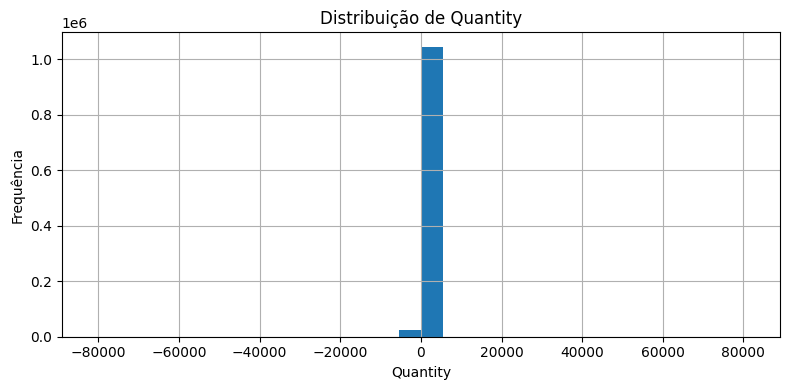

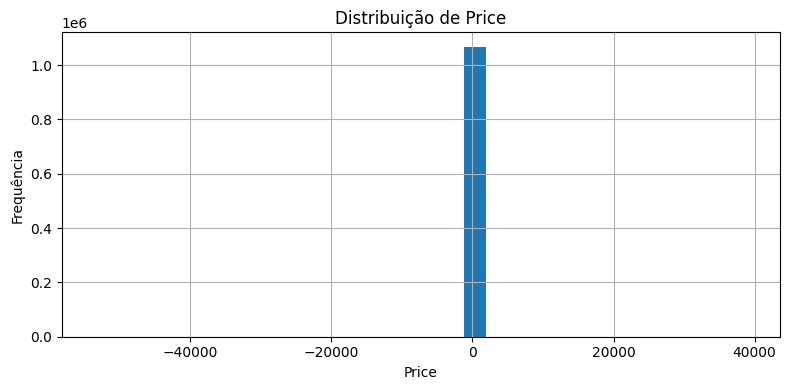

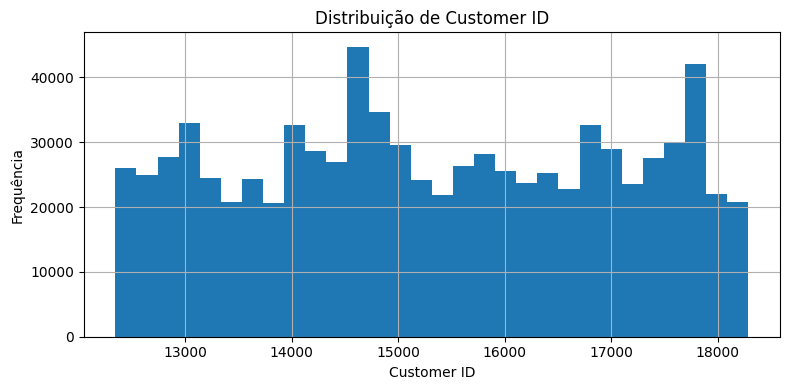

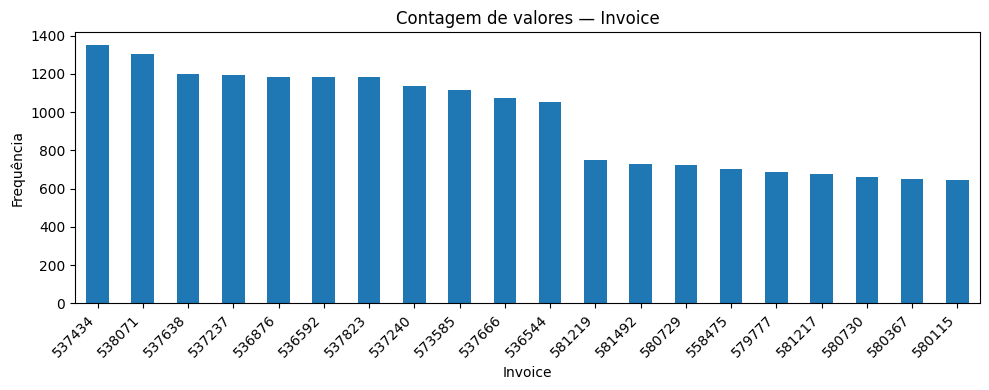

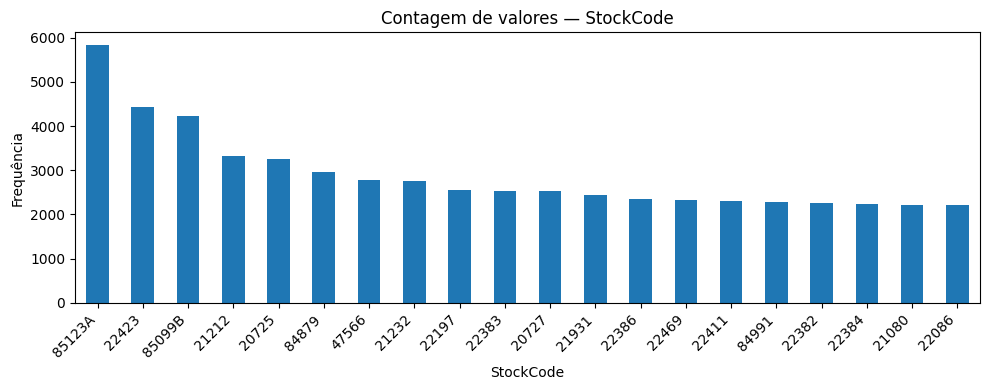

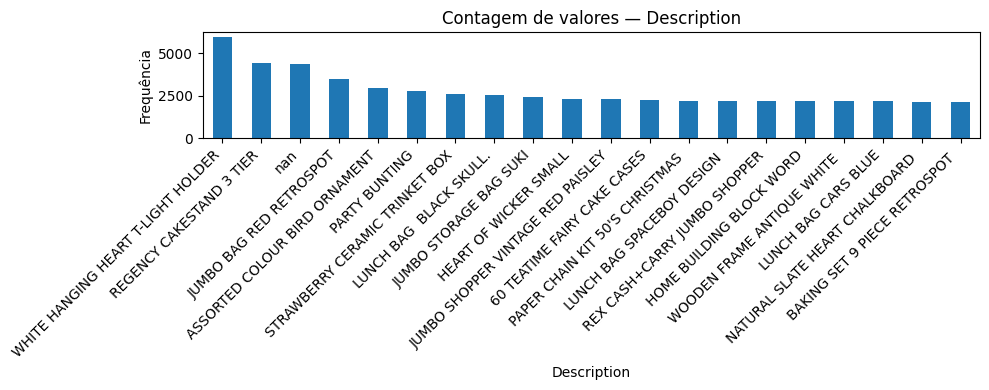

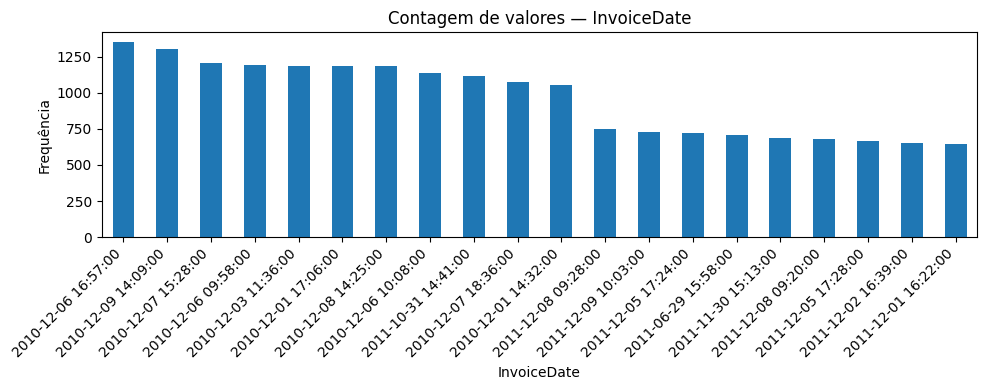

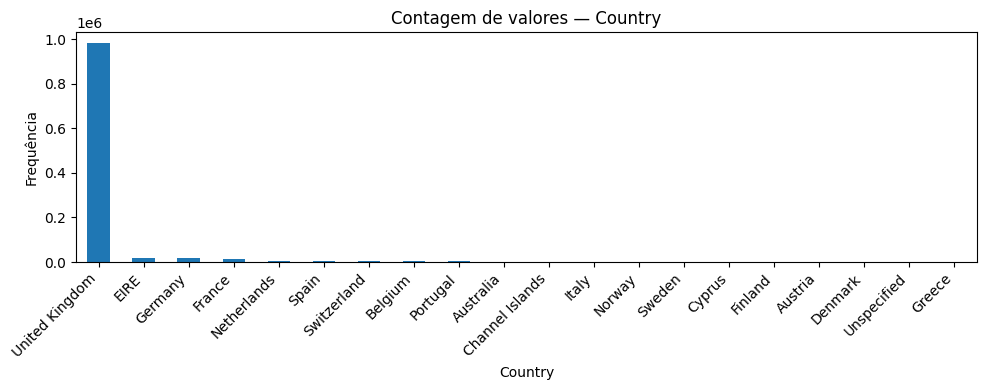

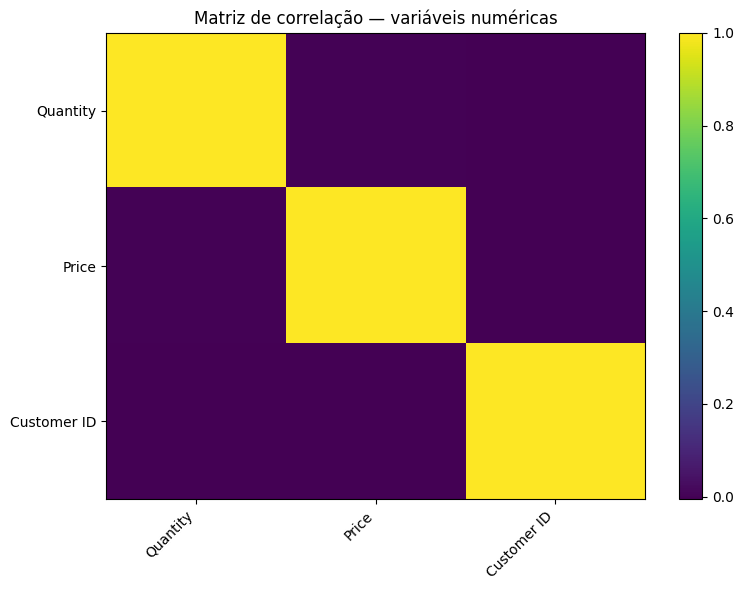

In [6]:
# Visualizações exploratórias básicas
# O grupo deve adaptar as colunas às características do dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=30)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()

def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Contagem de valores — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)

    if numericas.shape[1] < 2:
        print("Não há pelo menos duas variáveis numéricas para calcular correlação.")
        return

    corr = numericas.corr()

    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Quantity', 'Price', 'Customer ID']
cats = ['Invoice', 'StockCode', 'Description', 'InvoiceDate', 'Country']

[ plot_distribuicao_numerica(df, n) for n in nums ]
[ plot_contagem_categorica(df, c) for c in cats ]
plot_matriz_correlacao(df)


## 2.2 Análise visual — interpretação

A distribuição de Quantity, conforme o histograma apresentado, revela forte concentração de valores próximos de zero, com a maior parte das observações situada em uma faixa estreita ao redor de pequenas quantidades. Ao mesmo tempo, observa-se a presença de valores extremos tanto negativos quanto positivos, evidenciados pela extensão do eixo até aproximadamente −80.000 e +80.000. Esse comportamento indica claramente a existência de outliers, que, no contexto do dataset, são compatíveis com devoluções (quantidades negativas) ou registros anômalos. Esse padrão impacta diretamente a mineração de padrões frequentes, pois transações com quantidades negativas ou muito elevadas podem distorcer a composição dos itemsets se não forem filtradas adequadamente.


A distribuição de Price apresenta comportamento semelhante, com alta concentração em valores baixos e presença de valores extremos negativos e positivos. A existência de preços negativos sugere registros inconsistentes ou ajustes financeiros, o que não é incomum em dados reais, mas exige tratamento. Para a tarefa de padrões frequentes, embora o preço não seja diretamente utilizado na definição de itemsets, sua distribuição reforça a necessidade de limpeza prévia para evitar que transações inválidas influenciem a construção das cestas.


A variável Customer ID apresenta uma distribuição relativamente espalhada ao longo de um intervalo contínuo, sem concentração evidente em poucos valores, o que é consistente com seu papel de identificador. Não há indicação de desbalanceamento relevante nesse gráfico, mas também não há informação suficiente aqui para inferir frequência de compras por cliente, já que o histograma reflete apenas a distribuição dos identificadores, não sua recorrência. Portanto, esse gráfico tem utilidade limitada para a tarefa de mineração de padrões frequentes.


As contagens de Invoice indicam que não há concentração extrema em poucas transações; as frequências mostradas são relativamente próximas entre si dentro do subconjunto exibido. Isso sugere que não há um pequeno conjunto de invoices dominando o dataset, o que é desejável para evitar viés em padrões frequentes. Ainda assim, como cada invoice representa uma transação, o mais relevante não é sua frequência absoluta, mas o número de itens associados a cada uma, o que não é capturado diretamente nesse gráfico.


No caso de StockCode, observa-se uma distribuição com cauda longa, em que poucos produtos aparecem com alta frequência enquanto muitos outros têm frequência menor. Esse padrão é típico de dados de varejo e indica desbalanceamento entre itens populares e itens raros. Esse aspecto é crítico para mineração de padrões frequentes, pois itens muito raros tendem a não aparecer em regras relevantes, mas aumentam significativamente o espaço de busca, afetando eficiência e escalabilidade.


A análise de Description reforça esse comportamento, mostrando que algumas descrições aparecem com frequência significativamente maior do que outras. No entanto, a presença de valores como “nan” entre os mais frequentes indica problemas de qualidade de dados. Além disso, a variabilidade textual pode levar à fragmentação de itens semanticamente idênticos, o que afeta diretamente a qualidade dos padrões extraídos e a usabilidade dos resultados.


A distribuição de InvoiceDate, conforme apresentada, não evidencia diretamente tendências temporais, mas sugere que há uma dispersão razoável ao longo do tempo. Ainda assim, como o gráfico mostra apenas contagens pontuais, não é possível inferir sazonalidade ou padrões temporais mais complexos sem agregações adicionais. Para mineração de padrões frequentes, isso não é central, mas pode ser relevante caso se deseje segmentar por período.


O gráfico de Country evidencia um forte desbalanceamento, com predominância massiva de transações do “United Kingdom” em comparação aos demais países. Esse padrão indica que os itemsets frequentes extraídos tenderão a refletir majoritariamente o comportamento desse país, reduzindo a representatividade de outros contextos. Isso tem implicações tanto para a validade dos padrões quanto para a diretriz de usabilidade, pois os resultados podem não ser generalizáveis.


Por fim, a matriz de correlação entre variáveis numéricas mostra ausência de correlação linear significativa entre Quantity, Price e Customer ID. Isso é consistente com a natureza dos dados (identificadores e atributos independentes) e indica que não há redundância evidente entre essas variáveis. Para a tarefa de mineração de padrões frequentes, esse resultado reforça que essas variáveis não agregam valor direto na formação de itemsets, sendo mais úteis como suporte para filtragem e limpeza.


No conjunto, os gráficos indicam a presença de concentração em poucos itens, valores extremos relevantes, categorias raras e desbalanceamento geográfico significativo. Esses fatores afetam diretamente tanto a eficiência (devido à alta cardinalidade e presença de itens raros) quanto a usabilidade (devido à possível baixa interpretabilidade e viés dos padrões), exigindo decisões cuidadosas na etapa de preparação dos dados.


In [7]:
# Detecção simples de outliers em variáveis numéricas usando IQR
# Esta função é um exemplo. O grupo deve avaliar se o critério faz sentido para cada atributo.

def detectar_outliers_iqr(df: pd.DataFrame, coluna: str) -> pd.DataFrame:
    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

    print(f"Coluna: {coluna}")
    print(f"Q1: {q1}")
    print(f"Q3: {q3}")
    print(f"IQR: {iqr}")
    print(f"Limite inferior: {limite_inferior}")
    print(f"Limite superior: {limite_superior}")
    print(f"Número de outliers: {len(outliers)}")

    return outliers

# Exemplo de uso:
nums = ['Quantity', 'Price', 'Customer ID']
for n in nums:
    display(detectar_outliers_iqr(df, n).head())


Coluna: Quantity
Q1: 1.0
Q3: 10.0
IQR: 9.0
Limite inferior: -12.5
Limite superior: 23.5
Número de outliers: 116489


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
10,489435,22195,HEART MEASURING SPOONS LARGE,24,2009-12-01 07:46:00,1.65,13085.0,United Kingdom


Coluna: Price
Q1: 1.25
Q3: 4.15
IQR: 2.9000000000000004
Limite inferior: -3.1000000000000005
Limite superior: 8.5
Número de outliers: 68105


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
35,489437,21360,JOY LARGE WOOD LETTERS,1,2009-12-01 09:08:00,9.95,15362.0,United Kingdom
38,489437,35400,WOODEN BOX ADVENT CALENDAR,2,2009-12-01 09:08:00,8.95,15362.0,United Kingdom
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.0,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA
131,489445,22180,RETRO SPOT LAMP,2,2009-12-01 09:57:00,9.95,17519.0,United Kingdom


Coluna: Customer ID
Q1: 13975.0
Q3: 16797.0
IQR: 2822.0
Limite inferior: 9742.0
Limite superior: 21030.0
Número de outliers: 0


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


## 2.3 Problemas de qualidade dos dados

| Problema identificado                                             | Evidência                                                                                                                  |
| ----------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------- |
| Valores ausentes em `Customer ID` e `Description`                 | Conhecimento do dataset e presença de “nan” entre valores frequentes em `Description` (gráfico de contagem)                |
| Duplicatas (linhas repetidas de transações)                       | Estrutura transacional (Invoice–StockCode) sugere possibilidade de múltiplas linhas idênticas; padrão conhecido do dataset |
| Outliers em `Quantity` e `Price`                                  | Histogramas mostram valores extremos negativos e positivos (caudas longas)                                                 |
| Categorias raras em `StockCode` e `Description`                   | Gráficos de contagem mostram poucos itens com alta frequência e muitos com baixa frequência (cauda longa)                  |
| Atributos sensíveis ou identificadores (`Invoice`, `Customer ID`) | Alta cardinalidade e papel estrutural identificado nos gráficos e descrição dos dados                                      |

<br><br>

| Decisão tomada                                                                     | Justificativa                                                                                                                          |
| ---------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------- |
| Remover `Customer ID` e manter `Description` com limpeza (remoção/ajuste de nulos) | `Customer ID` não é necessário para mineração de itemsets e sua ausência é alta; `Description` é essencial para interpretabilidade     |
| Remover duplicatas exatas                                                          | Duplicatas artificiais inflacionam suporte de itemsets e distorcem regras de associação                                                |
| Remover valores negativos e extremos inconsistentes                                | Valores negativos indicam devoluções e podem distorcer padrões; extremos podem ser ruído                                               |
| Filtrar itens abaixo de um limiar mínimo de suporte                                | Reduz o espaço de busca e melhora eficiência sem perda relevante de padrões                                                            |
| Remover `Customer ID`; manter `Invoice` apenas como agrupador                      | Identificadores não contribuem diretamente para padrões e aumentam dimensionalidade; `Invoice` é necessário para estruturar transações |



### Observação sobre responsabilidade

A remoção de Customer ID, motivada pela alta taxa de valores ausentes e pela irrelevância direta para a formação de itemsets, contribui positivamente para eficiência, ao reduzir a dimensionalidade e eliminar um atributo de alta cardinalidade. No entanto, essa decisão elimina a possibilidade de análises centradas no cliente, como segmentação ou personalização, o que pode limitar a usabilidade em cenários onde a interpretação dos padrões depende do perfil do consumidor. Ainda assim, dado que o objetivo específico é mineração de padrões frequentes entre itens, essa perda é aceitável no contexto definido.

A limpeza da variável Description, com manutenção após tratamento de valores ausentes, atende diretamente à diretriz de usabilidade. Sem essa etapa, os padrões gerados tenderiam a ser pouco interpretáveis, especialmente se baseados apenas em StockCode. Ao preservar e padronizar descrições textuais, melhora-se a acessibilidade dos resultados para usuários não técnicos. Por outro lado, essa escolha pode introduzir custo adicional de processamento, especialmente se envolver normalização textual mais sofisticada, o que impacta marginalmente a eficiência.

A remoção de duplicatas exatas é uma decisão alinhada tanto com eficiência quanto com qualidade analítica. Do ponto de vista computacional, reduz o volume de dados a ser processado; do ponto de vista analítico, evita inflar artificialmente o suporte de determinados itemsets, o que poderia comprometer a confiabilidade dos padrões. Não há impacto negativo relevante sobre usabilidade, sendo uma decisão praticamente necessária.

O tratamento de outliers, especialmente a remoção de valores negativos em Quantity e Price, melhora a consistência dos dados e evita que transações de devolução ou registros anômalos distorçam os padrões frequentes. Essa decisão favorece tanto a eficiência (ao reduzir ruído e complexidade) quanto a usabilidade, pois os padrões extraídos passam a refletir compras efetivas. No entanto, há uma perda de informação: devoluções são um fenômeno real e podem ser relevantes em outros tipos de análise. A exclusão, portanto, deve ser entendida como uma simplificação orientada ao objetivo específico da tarefa.

A filtragem de categorias raras, baseada na distribuição observada de StockCode e Description, é uma das decisões com maior impacto em eficiência e escalabilidade. Ao eliminar itens com suporte muito baixo, reduz-se significativamente o espaço de busca dos algoritmos de mineração, tornando a execução viável em termos de tempo e memória. Contudo, essa decisão tem implicações diretas na usabilidade: padrões envolvendo itens raros deixam de ser descobertos, o que pode ser problemático em contextos onde esses itens têm alto valor estratégico. Trata-se, portanto, de um trade-off clássico entre completude e viabilidade computacional.

Por fim, o tratamento de identificadores como Invoice, mantido apenas como estrutura de agrupamento, é essencial para preservar a semântica transacional dos dados sem introduzir ruído analítico. Essa decisão melhora a eficiência ao evitar a inclusão de atributos irrelevantes no espaço de mineração e não compromete a usabilidade, já que o identificador não é necessário na interpretação dos padrões.

Em conjunto, as decisões refletem uma priorização clara da viabilidade computacional e da clareza interpretativa dos resultados, ainda que à custa da remoção de certas informações potencialmente úteis em análises mais amplas.


In [8]:
def preparar_dados_basico(
    df: pd.DataFrame,
    colunas_remover=None,
    imputar_numericas=False,
    imputar_categoricas=True,
    remover_outliers=True,
    filtrar_itens_raros=True,
    min_suporte_item=0.001
) -> pd.DataFrame:
    df_prep = df.copy()

    # 1. Remover duplicatas exatas
    df_prep = df_prep.drop_duplicates()

    # 2. Remover colunas irrelevantes / identificadores
    if colunas_remover is None:
        colunas_remover = [
            "Customer ID"  # conforme decisão
        ]

    colunas_existentes = [col for col in colunas_remover if col in df_prep.columns]
    df_prep = df_prep.drop(columns=colunas_existentes)

    # 3. Tratamento de valores ausentes
    # Numéricas: não imputar por padrão (evita distorcer lógica transacional)
    if imputar_numericas:
        for col in df_prep.select_dtypes(include=np.number).columns:
            df_prep[col] = df_prep[col].fillna(df_prep[col].median())

    # Categóricas: manter consistência mínima
    if imputar_categoricas:
        for col in df_prep.select_dtypes(include=["object", "category"]).columns:
            df_prep[col] = df_prep[col].fillna("desconhecido")

    # 4. Remoção de outliers relevantes para a tarefa
    if remover_outliers:
        if "Quantity" in df_prep.columns:
            df_prep = df_prep[df_prep["Quantity"] > 0]

        if "Price" in df_prep.columns:
            df_prep = df_prep[df_prep["Price"] > 0]

    # 5. Padronização de descrição
    if "Description" in df_prep.columns:
        df_prep["Description"] = df_prep["Description"].str.strip().str.lower()

    # 6. Filtragem de itens raros (baseado em StockCode)
    if filtrar_itens_raros and "StockCode" in df_prep.columns:
        freq = df_prep["StockCode"].value_counts(normalize=True)
        itens_validos = freq[freq >= min_suporte_item].index
        df_prep = df_prep[df_prep["StockCode"].isin(itens_validos)]

    # 7. Estruturação transacional (Invoice -> lista de itens)
    if "Invoice" in df_prep.columns and "StockCode" in df_prep.columns:
        df_transacoes = (
            df_prep
            .groupby("Invoice")["StockCode"]
            .apply(list)
            .reset_index(name="itens")
        )
        return df_transacoes

    return df_prep


df_prep = preparar_dados_basico(df)
display(df_prep.head())


,Invoice,itens
0,489434,"[21232, 21523]"
1,489436,"[21755, 21754, 84879, 21181, 22111]"
2,489437,"[84970S, 20971, 22111, 22112]"
3,489438,[20711]
4,489439,"[22138, 22139, 22352, 21731, POST]"


## 2.4 Justificativa da preparação dos dados

A preparação dos dados foi orientada pela necessidade de transformar o dataset em uma estrutura adequada para mineração de padrões frequentes, isto é, um conjunto de transações em que cada fatura representa uma cesta de itens. Por esse motivo, algumas colunas foram mantidas apenas com função estrutural, enquanto outras foram removidas. A coluna Customer ID foi removida porque possui valores ausentes e não é necessária para a tarefa principal, já que o objetivo é identificar associações entre produtos, não perfis de clientes. A coluna Invoice, por outro lado, foi mantida apenas como identificador de transação para agrupar os itens comprados em uma mesma cesta, mas não foi usada como item minerável.

Os valores ausentes foram tratados de acordo com sua relevância para a tarefa. Ausências em Customer ID não comprometem a mineração de padrões frequentes entre produtos, portanto a solução mais adequada foi remover essa coluna em vez de descartar linhas inteiras. Já em Description, os valores ausentes exigem tratamento mais cuidadoso, pois essa coluna contribui para a interpretação dos resultados. Quando a descrição estava ausente ou inconsistente, a representação principal do item foi baseada em StockCode, preservando a identificação do produto sem depender exclusivamente do texto descritivo.

As variáveis categóricas foram tratadas de forma seletiva. StockCode foi utilizado como identificador principal dos itens, pois tende a ser mais estável do que Description. A variável Description foi preservada como apoio interpretativo, permitindo apresentar os padrões de maneira mais compreensível. Country não foi incorporado diretamente à mineração inicial, pois sua forte predominância do Reino Unido poderia fazer com que os padrões refletissem majoritariamente esse mercado. Caso usada futuramente, ela deve servir para segmentação ou análise comparativa, não como item da cesta.

Não houve necessidade de normalização numérica, pois algoritmos de padrões frequentes trabalham com presença ou ausência de itens, e não com distância, escala ou magnitude contínua. Também não foi aplicada discretização de Quantity ou Price, já que essas variáveis não foram usadas diretamente na formação dos itemsets. A principal codificação realizada foi a transformação transacional: os dados foram reorganizados de linhas individuais de produtos para uma estrutura do tipo transação–item, geralmente em formato binário, indicando se determinado item aparece ou não em uma fatura.

A remoção de outliers foi aplicada principalmente a registros com Quantity e Price negativos ou inconsistentes. Valores negativos em Quantity costumam indicar devoluções, cancelamentos ou ajustes, enquanto preços negativos não representam compras convencionais. Esses registros foram removidos porque poderiam gerar cestas artificiais e distorcer o cálculo de suporte dos itemsets. Também foram consideradas categorias muito raras, especialmente em StockCode e Description, que podem ser filtradas por um limiar mínimo de suporte para reduzir ruído e tornar o processamento viável.

Essas decisões introduzem riscos. A remoção de Customer ID impede análises por perfil de cliente. A remoção de devoluções elimina um fenômeno real do varejo, que poderia ser relevante em outra tarefa analítica. A filtragem de itens raros pode excluir produtos pouco frequentes, mas potencialmente importantes. Além disso, usar StockCode como base principal melhora a consistência, mas pode reduzir a legibilidade caso os códigos não sejam acompanhados das descrições correspondentes.

Em relação à diretriz de eficiência e escalabilidade, as decisões reduzem volume, cardinalidade e ruído, tornando a mineração mais viável computacionalmente. A remoção de identificadores desnecessários, duplicatas, outliers e itens raros diminui o espaço de busca dos algoritmos e evita explosão combinatória. Em relação à diretriz de usabilidade e acessibilidade, a manutenção de Description como apoio interpretativo é essencial para que os padrões extraídos sejam compreensíveis por usuários não técnicos. Assim, a preparação buscou equilibrar desempenho computacional e clareza dos resultados, sem tratar a limpeza dos dados como mera sequência de comandos.


## 2.5 Interações com LLM — Data Understanding & Data Preparation

### Subtarefa comparável

Nesta etapa, as duas trilhas devem receber a mesma subtarefa geral.

**Subtarefa escolhida:** propor estratégias de limpeza, transformação e preparação dos dados para a tarefa de mineração

---

### Trilha A — baseline

**Modelo utilizado:** ChatGPT Instant 5.3  
**Data de acesso:** 01/05/2026 e 02/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f63eea-3610-83e9-a188-e80f8e417b4d

#### Prompt principal — baseline

```text
Tenho um dataset com as seguintes colunas: Colunas numéricas: ['Quantity', 'Price', 'Customer ID'] e Colunas não numéricas: ['Invoice', 'StockCode', 'Description', 'InvoiceDate', 'Country'], do dataset online_retail_II.csv, disponivel no kaggle. A tarefa de mineração é padroes frequentes. Sugira uma estratégia de Data Understanding e Data Preparation para preparar os dados para essa tarefa.
```

#### Síntese da resposta da LLM

Para mineração de padrões frequentes, o ponto central é que os algoritmos, como Apriori ou FP-Growth, operam sobre conjuntos discretos de itens organizados em transações. Portanto, tanto o Data Understanding quanto o Data Preparation devem ser orientados a transformar o dataset em uma estrutura de cestas de compra, em que cada transação contém um conjunto de itens adquiridos conjuntamente.

No Data Understanding, é fundamental compreender o processo gerador dos dados. Nesse dataset, a unidade de análise correta é a transação representada por Invoice, enquanto os itens são representados por StockCode ou Description. É necessário identificar e tratar problemas típicos, como invoices canceladas (geralmente iniciadas por “C”), quantidades negativas associadas a devoluções, códigos de produto que não representam itens reais e valores ausentes em Customer ID. Além disso, deve-se analisar distribuições relevantes, como o número de itens por transação, a frequência dos produtos e o grau de esparsidade dos dados, pois essas características influenciam diretamente a escolha de parâmetros como suporte mínimo.

No Data Preparation, o primeiro passo é a limpeza dos dados, removendo transações canceladas, registros com quantidade menor ou igual a zero e itens inválidos. Em seguida, define-se o identificador do item, sendo recomendável utilizar StockCode por sua consistência, mantendo Description apenas para interpretação posterior. Depois, os dados devem ser agregados por Invoice, formando conjuntos de itens únicos por transação. Nesse ponto, é necessário decidir explicitamente se a quantidade será considerada; na abordagem clássica de market basket analysis, utiliza-se apenas a presença binária do item.

Após a construção das transações, os dados devem ser convertidos para uma representação adequada, como uma matriz binária no formato one-hot encoding, em que cada linha corresponde a uma transação e cada coluna a um item. Devido à alta dimensionalidade típica desse tipo de dado, é essencial aplicar redução, removendo itens com baixa frequência ou limitando o conjunto aos itens mais relevantes, sob risco de inviabilizar computacionalmente a mineração.

Por fim, pode-se aplicar segmentações para melhorar a qualidade dos padrões extraídos, como por país, cliente ou período temporal. É importante evitar erros conceituais, como tratar variáveis numéricas como Price como itens ou utilizar Customer ID na composição das cestas, pois isso compromete a validade dos padrões encontrados.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT Instant 5.3  
**Data de acesso:** 01/05/2026 e 02/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f63eea-3610-83e9-a188-e80f8e417b4d

#### Prompt principal — guiado

```text
Tenho um dataset com as seguintes colunas: Colunas numéricas: ['Quantity', 'Price', 'Customer ID'] e Colunas não numéricas: ['Invoice', 'StockCode', 'Description', 'InvoiceDate', 'Country'], do dataset online_retail_II.csv, disponivel no kaggle. A tarefa de mineração é padroes frequentes. Sugira uma estratégia de Data Understanding e Data Preparation para preparar os dados para essa tarefa.

Considere explicitamente as diretrizes de IA responsavel:
1. “Eficiência e escalabilidade”
2. “Usabilidade e acessibilidade”

Ao sugerir a preparação, indique:
- possíveis atributos sensíveis, se houver;
- riscos de viés ou perda de informação;
- decisões que devem ser documentadas;
- transformações necessárias;
- limitações e trade-offs.
```

#### Síntese da resposta da LLM

Para mineração de padrões frequentes nesse dataset (transações de varejo), o ponto central é reinterpretar os dados no formato de “cestas de itens” (market basket), onde cada transação contém um conjunto de produtos. A estratégia de Data Understanding deve começar pela caracterização semântica das colunas. “Invoice” funciona como identificador de transação; “StockCode” e “Description” representam o item; “Quantity” e “Price” trazem atributos quantitativos que podem ser úteis para filtragem; “InvoiceDate” permite análises temporais; “Country” segmenta o contexto geográfico; e “Customer ID” identifica o cliente, embora nem sempre esteja preenchido. É importante verificar inconsistências típicas desse dataset, como valores negativos em “Quantity” (indicando devoluções), preços zerados, duplicidades e descrições inconsistentes para um mesmo código de produto. Também convém avaliar cardinalidade e sparsidade, já que mineração de padrões frequentes é sensível ao número de itens distintos e ao tamanho médio das transações.

Na preparação dos dados, a transformação fundamental é converter o dataset em uma estrutura transacional: agrupar por “Invoice” e mapear cada fatura para o conjunto de “StockCode” (ou “Description”) adquiridos. Antes disso, é necessário filtrar ruídos: remover transações canceladas (tipicamente identificadas por prefixos específicos em “Invoice” ou quantidades negativas), excluir itens com “Quantity” ≤ 0 e preços inválidos, e tratar valores ausentes (por exemplo, descartar “Customer ID” se não for usado ou imputá-lo apenas se houver justificativa clara). A escolha entre “StockCode” e “Description” como identificador do item deve ser documentada, pois descrições podem conter variações textuais que fragmentam o suporte dos itens, enquanto códigos podem ser mais consistentes. Em seguida, pode-se binarizar as transações (presença/ausência de item) ou, se desejado, incorporar quantidade via discretização (por exemplo, “comprou muito” vs. “comprou pouco”), embora isso aumente a dimensionalidade.

Do ponto de vista de eficiência e escalabilidade, decisões como redução do espaço de itens são críticas. Pode-se remover itens muito raros (abaixo de um suporte mínimo preliminar) para evitar explosão combinatória em algoritmos como Apriori. Alternativamente, utilizar algoritmos mais eficientes como FP-Growth reduz custo computacional. A agregação por “Invoice” deve ser feita de forma vetorizada (por exemplo, via groupby) e, dependendo do tamanho, pode exigir processamento incremental ou uso de estruturas esparsas. Há um trade-off direto entre granularidade e custo: manter todos os itens preserva informação, mas pode tornar a mineração inviável; filtrar agressivamente melhora desempenho, mas pode eliminar padrões relevantes de nicho.

Em termos de usabilidade e acessibilidade, é importante produzir um pipeline de preparação claro, reprodutível e bem documentado, com parâmetros explícitos (por exemplo, limiar de suporte mínimo, critérios de filtragem). A representação final (como matriz binária ou lista de transações) deve ser compatível com bibliotecas padrão (mlxtend, por exemplo), facilitando uso por outros usuários. Também é relevante garantir que decisões de limpeza e transformação sejam transparentes e configuráveis, permitindo adaptação a diferentes cenários de negócio.

Quanto a atributos sensíveis, o dataset não contém dados pessoais diretos além de “Customer ID”, que pode ser considerado identificador indireto. Embora não haja atributos como gênero ou renda, ainda existe risco de inferência indireta de comportamento de consumo por cliente ou país. Portanto, deve-se avaliar se a análise será feita em nível agregado (por transação) ou individual (por cliente). Se “Customer ID” não for essencial, sua remoção ou anonimização reduz riscos. “Country” pode introduzir vieses geográficos, especialmente se padrões forem interpretados como preferências culturais sem contexto adequado.

Os riscos de viés e perda de informação aparecem principalmente nas etapas de filtragem. Remover devoluções pode eliminar padrões relevantes de insatisfação; excluir itens raros pode apagar comportamentos minoritários; padronizar descrições pode fundir produtos distintos. Além disso, a ausência de “Customer ID” em parte dos dados pode enviesar análises baseadas em clientes. Essas decisões devem ser explicitamente documentadas, incluindo justificativas e impacto esperado nos resultados. Também é importante registrar versões do dataset e parâmetros usados, garantindo rastreabilidade.

As limitações e trade-offs são inerentes ao problema. A modelagem transacional ignora ordem temporal dentro da fatura e relações entre compras ao longo do tempo, o que pode ser relevante em certos contextos. A binarização perde informação de quantidade e valor monetário, simplificando o problema em troca de viabilidade computacional. Já a inclusão de atributos adicionais (como tempo ou localização) pode enriquecer a análise, mas exige técnicas mais complexas (por exemplo, mineração sequencial ou multidimensional). Portanto, a estratégia deve equilibrar fidelidade ao dado original, custo computacional e clareza interpretativa, sempre com documentação rigorosa das escolhas feitas.


## 2.6 Comparação crítica — Data Understanding & Preparation

| Aspecto                     | Trilha A — baseline                                                                            | Trilha B — guiada                                                                                                         | Decisão do grupo            |
| --------------------------- | ---------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------- | --------------------------- |
| Tratamento de nulos         | Menciona valores ausentes em `Customer ID`, mas não detalha estratégia explícita de tratamento | Propõe explicitamente descartar `Customer ID` ou imputar apenas com justificativa, além de exigir documentação da decisão | Aceitar Trilha B |
| Tratamento de outliers      | Sugere remoção de quantidades negativas e transações canceladas como parte da limpeza          | Detalha remoção de `Quantity ≤ 0`, preços inválidos e discute impacto dessa remoção (ex.: devoluções)                     | Aceitar |
| Atributos sensíveis         | Não aborda explicitamente atributos sensíveis ou riscos associados                             | Identifica `Customer ID` como identificador indireto e discute risco de inferência, além de viés geográfico em `Country`  | Aceitar Trilha B |
| Codificação de variáveis    | Propõe one-hot encoding após agregação transacional (matriz binária)                           | Propõe binarização e menciona alternativa de discretização de quantidade, com impacto na dimensionalidade                 | Corrigir |
| Redução de dimensionalidade | Recomenda remover itens de baixa frequência para evitar inviabilidade computacional            | Discute explicitamente o trade-off entre filtragem de itens raros e perda de padrões de nicho                             | Corrigir |
| Justificativa técnica       | Focada na adequação ao algoritmo (Apriori/FP-Growth) e estrutura transacional                  | Amplia justificativa incluindo documentação, reprodutibilidade, trade-offs e impacto das decisões                         | Aceitar |
| Riscos e limitações         | Implícitos (ex.: perda de informação ao filtrar), mas não discutidos diretamente               | Explicitamente discute perda de informação, viés, limitações da modelagem e necessidade de rastreabilidade                | Rejeitar |


### Análise crítica

A comparação mostra que a resposta guiada por diretrizes de IA responsável foi mais completa, principalmente porque tornou explícitas decisões que, na resposta baseline, apareciam apenas como recomendações técnicas gerais. A Trilha A sugeriu corretamente a estrutura central da tarefa: transformar o dataset em cestas de itens agrupadas por Invoice, usar StockCode ou Description como item, remover transações canceladas e aplicar codificação binária. Porém, ela ficou incompleta ao não discutir suficientemente riscos, justificativas documentáveis e implicações das escolhas de preparação.

A Trilha B também sugeriu corretamente a transformação transacional, o uso preferencial de StockCode, a filtragem de registros inválidos e a preocupação com cardinalidade e esparsidade. Além disso, foi superior ao tratar explicitamente Customer ID como identificador indireto, ao relacionar Country a possíveis vieses geográficos e ao discutir os trade-offs entre eficiência computacional e perda de informação. Por isso, o grupo aceitou a Trilha B nos aspectos de tratamento de nulos e atributos sensíveis, pois ela apresentou uma justificativa mais alinhada às diretrizes escolhidas.

No tratamento de outliers, as duas respostas foram aceitas. Ambas indicaram corretamente que registros com Quantity ≤ 0, preços inválidos e invoices canceladas devem ser tratados antes da mineração, pois podem representar devoluções, cancelamentos ou registros incompatíveis com a ideia de cesta de compra. A Trilha B foi mais completa por mencionar que remover devoluções também elimina um fenômeno real do varejo, mas a decisão permanece adequada para a tarefa específica de padrões frequentes de compra.

Na codificação de variáveis, o grupo decidiu corrigir a proposta. A ideia de one-hot encoding ou binarização das transações está tecnicamente correta para mineração clássica de padrões frequentes. O ponto a corrigir é a sugestão de discretizar quantidade, pois isso mudaria a natureza da tarefa e aumentaria a dimensionalidade sem necessidade para o objetivo definido. A preparação mais adequada é usar presença ou ausência de StockCode por Invoice, mantendo Quantity apenas como filtro de validade.

Na redução de dimensionalidade, o grupo também decidiu corrigir. A recomendação de remover itens raros é tecnicamente plausível, mas não deve ser aplicada de forma automática antes da mineração sem critério explícito, porque pode eliminar padrões relevantes de nicho. A correção é tratar essa filtragem como uma decisão parametrizada, vinculada ao suporte mínimo e documentada como trade-off entre eficiência e perda de informação.

Quanto à justificativa técnica, a decisão foi aceitar. A Trilha B melhora a resposta baseline ao explicar não apenas o que fazer, mas por que fazer, incluindo documentação, reprodutibilidade e impacto das escolhas. Esse ponto é importante porque a preparação de dados, no CRISP-DM, não deve ser apenas uma sequência operacional de filtros e agregações, mas uma etapa justificada com base na tarefa de mineração.

O item de riscos e limitações foi rejeitado na decisão do grupo, porque a formulação da Trilha B ampliou demais o escopo, incluindo riscos que não eram centrais para a tarefa ou que não estavam suficientemente apoiados por evidências empíricas diretas. A correção seria manter apenas limitações diretamente relacionadas à preparação proposta: perda de devoluções, perda de itens raros, redução de análises por cliente após remover Customer ID e possível predominância do Reino Unido caso Country seja usado para interpretação.

Quanto a erros técnicos, não foram encontrados erros graves no raciocínio geral das respostas. As principais fragilidades foram de escopo e precisão: a discretização de quantidade foi uma sugestão possível, mas pouco adequada para esta tarefa; a remoção de itens raros foi apresentada de modo forte demais sem definir limiar; e a discussão de riscos na Trilha B ficou mais ampla do que o necessário. Assim, o problema não foi uma conclusão tecnicamente falsa, mas a necessidade de corrigir algumas recomendações para manter a preparação mais consistente com mineração clássica de padrões frequentes.


# 3. Modeling

Nesta seção, o grupo deve documentar a modelagem proposta com apoio da LLM.

Para o TP de padrões frequentes, a modelagem pode envolver, por exemplo:

- Apriori;
- FP-Growth;
- Eclat;
- regras de associação.

Para outros TPs, substituir pelos algoritmos pertinentes, como algoritmos de agrupamento ou classificação.

O foco da Fase 2 é comparar criticamente as soluções sugeridas pela LLM nas duas trilhas e, quando possível, executar testes preliminares para verificar a viabilidade das sugestões.


## 3.1 Interações com LLM — Modeling

### Subtarefa comparável

**Subtarefa escolhida:** Indicação dos algoritmos mais adequados para a tarefa, parâmetros iniciais recomendados, métricas para avaliar a relevância dos padrões e interpretação dos resultados

---

### Trilha A — baseline

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 02/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f5defb-caa8-83e9-a327-102eef9ac60b

#### Prompt principal — baseline

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Online Retail II UCI"(https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data). 
Proponha uma estratégia para a tarefa de Mineração de Padrões Frequentes e Regras de Associação (Market Basket Analysis). 
Indique os algoritmos mais adequados, os parâmetros iniciais recomendados, as métricas de interesse para avaliar a relevância dos padrões encontrados e como interpretar e comparar os resultados.

Exemplo:
Com base no dataset [NOME] e na tarefa [TAREFA], proponha uma estratégia de modelagem.
Indique algoritmos, parâmetros iniciais, métricas de avaliação e como comparar resultados.
```

#### Síntese da resposta da LLM

O LLM estrutura a modelagem de uma maneira simples, fornecendo um passo a passo padrão para a tarefa de mineração de padrões frequentes. A estratégia sugerida envolve o uso de Apriori como algoritmo principal e FP-Growth para comparação, isso sugere que o LLM não levou em consideração as características do dataset, já que o Apriori não é um método eficiente para se lidar com uma base de dados tão grande quanto a escolhida devido à possibilidade de esgotamento de memória.
Além disso, o LLM menciona casos de aplicação válidos, como recomendação conjunta, campanhas e bundles, e sugere visualizações como gráficos de barras e heatmaps. No entanto, a interpretação dos resultados ainda é muito voltada para o cientista de dados, exigindo um entendimento de métricas como o Lift e confidence.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 02/05/2026  
**Link da conversa:** https://chatgpt.com/share/69f5deeb-7ce8-83e9-903a-46b1871cbe1d

#### Prompt principal — guiado

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Online Retail II UCI" (https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci/data). 
A tarefa será Mineração de Padrões Frequentes e Extração de Regras de Associação (Market Basket Analysis). Ajude-me a criar uma estratégia técnica e metodológica para a Modelagem do problema, incluindo: 
- Algoritmos adequados: Seleção e justificativa de algoritmos (ex: Apriori, FP-Growth, Eclat, etc.) considerando as características do dataset. 
- Parâmetros iniciais: Sugestão justificada para os limiares de suporte mínimo e confiança mínima. 
- Métricas de avaliação e interesse: Como utilizar métricas avançadas (como Lift, Leverage, Conviction) para filtrar padrões triviais ou redundantes. 
- Riscos metodológicos 
- Trade-offs: Análise da relação entre desempenho/custo computacional, uso de memória e interpretabilidade dos padrões gerados.

Crucial: Você deve seguir estritamente as seguintes diretrizes de IA Responsável: 
1. Eficiência e Escalabilidade: O dataset é gigante. Proponha abordagens, pré-processamentos ou algoritmos que evitem o esgotamento de memória (RAM) e otimizem drasticamente o custo computacional. 
2. Usabilidade e Acessibilidade: O resultado final será lido por diretores de Marketing. Proponha como devemos exibir esses resultados (visualizações, gráficos) e como organizar o notebook para que as regras matemáticas sejam traduzidas de forma didática e acionável. 

Descreva como as diretrizes 1 e 2 influenciaram diretamente suas escolhas técnicas.

Exemplo:
Com base no dataset [NOME] e na tarefa [TAREFA], proponha uma estratégia de modelagem.

Considere explicitamente as diretrizes:
1. [DIRETRIZ 1]
2. [DIRETRIZ 2]

Na resposta, indique:
- algoritmos adequados;
- parâmetros iniciais;
- métricas de avaliação;
- riscos metodológicos;
- impacto das diretrizes nas escolhas;
- trade-offs entre desempenho, interpretabilidade, custo computacional e qualidade da solução.
```

#### Síntese da resposta da LLM

O LLM entrega uma estratégia mais refinada para o contexto do trabalho, tratando os desafios de um grande volume de dados e sugerindo formas de traduzir os aspectos muito técnicos. Isso demostra que o LLM conseguiu seguir as diretrizes propostas. 
A IA elege o FP-Growth como algoritmo principal por sua eficiência computacional, limitando o Apriori apenas para fins comparativos e estabelecendo táticas para evitar o esgotamento de memória. Além disso, estrutura a entrega final para o entendimento de pessoas não técnicas, traduzindo o jargão de ciência de dados para linguagem mais simples e propõe um painel visual focado em ações práticas, como sugestões de kits específicos.


## 3.2 Comparação das soluções sugeridas pela LLM

| Elemento | Trilha A — baseline | Trilha B — guiada | Diferença concreta? | Comentário do grupo |
|---|---|---|---|---|
| Algoritmos sugeridos | Apriori (principal), FP-Growth (secundário) | FP-Growth (principal), Apriori (secundário) | SIM | Necessidade de eficiencia computacional torna o FP-Growth mais apropriado |
| Parâmetros sugeridos | min_sup=0.1, min_conf=0.3 | min_sup = 0.5 ou 0.01, min_conf=0.35 a 0.5 | SIM | Trilha A não justifica o uso desses parâmetros e a trilha B muda os parametros sugeridos no meio da resposta |
| Métricas sugeridas | Support; Confidence; Lift; Leverage; Conviction | Support; Confidence; Lift; Leverage; Conviction.   | NÃO | Métricas comuns para a tarefa de modelagem de padrões frequentes |
| Preparação exigida | Remover linhas falhas | remover linhas falhas e redução de dimensionalidade | SIM | trilha B sugere uma preparação um pouco mais profunda |
| Interpretabilidade | Algoritmos escolhidos interpretáveis e dá exemplo de interpretação de um resultado | Algoritmos escolhidos interpretáveis | SIM | Trilha A deu instruções diretas de interpretação para métricas como Lift e confidence, enquanto a trilha B deu sugestões de como apresentar os resultados para outras pessoas |
| Custo computacional | Alto | Médio | SIM | Escolha de algoritmos mais eficiente da trilha B devido a base de dados grande |
| Riscos ou limitações | Não descreve | Regras espúrias, sazonalidade, itens ignorados, duplicação semântica | SIM | A falta de consideração por riscos na trilha A indica um plano raso |
| Aderência às diretrizes | Pouco | SIM | SIM | Trilha A tem pouca consideração sobre a eficiência e acessibilidade da modelagem, já a trilha B estruturou seu planejamento ao redor dessas diretrizes |

### Síntese

A trilha A cumpre o requisito básico de apresentar uma estratégia de modelagem de padrões frequentes, mas o faz de forma genérica. Já a Prompt B adapta a teoria às características da tarefa. Enquanto a alternativa A sugere parâmetros iniciais sem muita contextualização sobre o seu impacto, a alternativa B ajusta os parâmetros com uma justificativa clara, porém a LLM ainda se confunde e usa paramêtros diferentes nas seções 4 e 11. Além disso, A trilha B considera problemas do mundo real que a trilha A ignora com a listagem de riscos metodológicos

As diferenças mais clara estão nas diretrizes apontadas pela prompt. A trilha A entrega um roteiro de análise de dados padrão. Enquanto isso, a trilha B foca tanto em como o dado será consumido pelo tomador de decisão, propondo dashboards voltados para conversão de vendas e traduzindo os jargões de ciência de dados em linguagem clara, quanto em garantir a eficiência e escalabilidade da modelagem, ao propor algoritmos eficientes e estratégias de lidar com grandes volumes de dados.


## 3.3 Template de modelagem para padrões frequentes

Use esta subseção se o TP atual envolver mineração de padrões frequentes. Caso o TP atual seja de agrupamento ou classificação, esta subseção pode ser removida ou mantida como referência não executada.

> **Atenção:** suporte, confiança e lift devem ser interpretados no contexto do dataset. Valores de suporte muito baixos podem gerar muitas regras pouco úteis; valores muito altos podem ocultar padrões relevantes.


In [9]:
# CELULA MODIFICADA PARA O DATASET ONLINE RETAIL II
item_col = "itens"
def gerar_transacoes_de_coluna(df: pd.DataFrame, transaction_col: str, item_col: str) -> list:
    
    transacoes = df[item_col]
    return transacoes.tolist()

transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN, item_col)
print(f"Número de transações: {len(transacoes)}")
print(transacoes[0])


Número de transações: 33661
['21232', '21523']


In [10]:
# Exemplo de execução de Apriori e FP-Growth com mlxtend
# Esta célula é semi-funcional e depende da instalação da biblioteca mlxtend.
# O grupo deve ajustar suporte, confiança e métrica conforme o problema.

def executar_padroes_frequentes(transacoes, min_support=0.05, min_confidence=0.6):
    try:
        from mlxtend.preprocessing import TransactionEncoder
        from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
    except ImportError:
        print("Biblioteca mlxtend não instalada.")
        print("Instale com: pip install mlxtend")
        return None

    te = TransactionEncoder()
    matriz = te.fit(transacoes).transform(transacoes)
    df_transacoes = pd.DataFrame(matriz, columns=te.columns_)

    resultados = {}

    inicio = time.time()
    itemsets_apriori = apriori(
        df_transacoes,
        min_support=min_support,
        use_colnames=True
    )
    regras_apriori = association_rules(
        itemsets_apriori,
        metric="confidence",
        min_threshold=min_confidence
    )
    tempo_apriori = time.time() - inicio

    resultados["Apriori"] = {
        "itemsets": itemsets_apriori,
        "regras": regras_apriori,
        "tempo": tempo_apriori
    }

    inicio = time.time()
    itemsets_fpgrowth = fpgrowth(
        df_transacoes,
        min_support=min_support,
        use_colnames=True
    )
    regras_fpgrowth = association_rules(
        itemsets_fpgrowth,
        metric="confidence",
        min_threshold=min_confidence
    )
    tempo_fpgrowth = time.time() - inicio

    resultados["FP-Growth"] = {
        "itemsets": itemsets_fpgrowth,
        "regras": regras_fpgrowth,
        "tempo": tempo_fpgrowth
    }

    return resultados

# Exemplo de uso:
resultados = executar_padroes_frequentes(
    transacoes,
    min_support=0.01,
    min_confidence=0.3
)


In [11]:
# Resumo dos resultados de mineração de padrões frequentes.
# Esta célula não inventa resultados; ela apenas resume o que foi executado.

def resumir_resultados_padroes(resultados):
    if resultados is None:
        print("Nenhum resultado disponível.")
        return pd.DataFrame()

    linhas = []

    for algoritmo, info in resultados.items():
        itemsets = info["itemsets"]
        regras = info["regras"]

        linhas.append({
            "algoritmo": algoritmo,
            "n_itemsets": len(itemsets),
            "n_regras": len(regras),
            "tempo_segundos": round(info["tempo"], 4),
            "suporte_minimo_observado": itemsets["support"].min() if len(itemsets) > 0 else np.nan,
            "suporte_maximo_observado": itemsets["support"].max() if len(itemsets) > 0 else np.nan,
            "confianca_media": regras["confidence"].mean() if len(regras) > 0 else np.nan,
            "lift_medio": regras["lift"].mean() if len(regras) > 0 and "lift" in regras.columns else np.nan
        })

    return pd.DataFrame(linhas)

# Exemplo de uso:
resumo_modelagem = resumir_resultados_padroes(resultados)
display(resumo_modelagem)


,algoritmo,n_itemsets,n_regras,tempo_segundos,suporte_minimo_observado,suporte_maximo_observado,confianca_media,lift_medio
0,Apriori,1084,1309,4.5098,0.010012,0.159383,0.493168,9.54307
1,FP-Growth,1084,1309,1.1555,0.010012,0.159383,0.493168,9.54307


In [12]:
# Exemplo de variação de parâmetros
# Útil para verificar se os resultados são sensíveis às escolhas de suporte e confiança.

def testar_parametros_padroes(transacoes, suportes, confiancas):
    linhas = []

    for sup in suportes:
        for conf in confiancas:
            resultados = executar_padroes_frequentes(
                transacoes,
                min_support=sup,
                min_confidence=conf
            )

            resumo = resumir_resultados_padroes(resultados)

            if not resumo.empty:
                resumo["min_support"] = sup
                resumo["min_confidence"] = conf
                linhas.append(resumo)

    if len(linhas) == 0:
        return pd.DataFrame()

    return pd.concat(linhas, ignore_index=True)

# Exemplo de uso:
grade_resultados = testar_parametros_padroes(
    transacoes,
    suportes=[0.01, 0.03, 0.05],
    confiancas=[0.35, 0.5, 0.7]
)
display(grade_resultados)


,algoritmo,n_itemsets,n_regras,tempo_segundos,suporte_minimo_observado,suporte_maximo_observado,confianca_media,lift_medio,min_support,min_confidence
0,Apriori,1084,1052,2.4072,0.010012,0.159383,0.534689,10.053673,0.01,0.35
1,FP-Growth,1084,1052,1.1979,0.010012,0.159383,0.534689,10.053673,0.01,0.35
2,Apriori,1084,576,2.0241,0.010012,0.159383,0.630169,10.810008,0.01,0.50
3,FP-Growth,1084,576,1.1763,0.010012,0.159383,0.630169,10.810008,0.01,0.50
4,Apriori,1084,132,1.8617,0.010012,0.159383,0.763583,11.977082,0.01,0.70
5,FP-Growth,1084,132,1.2068,0.010012,0.159383,0.763583,11.977082,0.01,0.70
6,Apriori,179,32,0.3605,0.030035,0.159383,0.523152,7.211858,0.03,0.35
7,FP-Growth,179,32,0.8891,0.030035,0.159383,0.523152,7.211858,0.03,0.35
8,Apriori,179,19,0.3803,0.030035,0.159383,0.601291,8.000330,0.03,0.50
9,FP-Growth,179,19,1.0222,0.030035,0.159383,0.601291,8.000330,0.03,0.50


## 3.6 Resultados preliminares da modelagem

Podemos observar que a geração de regras é muito sensível ao suporte mínimo configurado. Com min_support = 0.01, os algoritmos encontraram 1084 itemsets frequentes. Variando a confiança neste nível de suporte, obtivemos 1052 regras com confiança de 0.35, 576 regras com confiança de 0.5 e 132 regras com confiança de 0.7. 

No entanto, ao aumentar o suporte para 0.03, o número de itemsets caiu drasticamente para 179, gerando um máximo de apenas 32 regras (para confiança de 0.35) e caindo para apenas 4 regras quando a confiança mínima foi ajustada. Elevando o suporte para 0.05, os algoritmos identificaram apenas 48 itemsets e nenhuma regra conseguiu ser formada, independentemente do limite de confiança. Isso indica que os produtos são comprados juntos com uma frequência absoluta relativamente baixa

As regras geradas no suporte de 0.01 possuem um lift médio considerável, variando entre 10 e 12. Isso aponta uma correlação forte entre os itens das regras geradas. A confiança média também foi alta, alcançando até 73,5% nos cenários mais restritivos.

O experimento valida a necessidade das diretrizes de escalabilidade. O algoritmo FP-Growth foi muito mais rápido, Enquanto o Apriori levou quase 5 segundos em uma das execuções, o FP-Growth entregou os mesmos resultados em cerca de 1 segundo.

### Se a tarefa for padrões frequentes

- número de padrões encontrados;
- número de regras geradas;
- suporte, confiança e lift;
- tempo de execução;
- redundância e interpretabilidade das regras.

### Atenção

Não conclua que um algoritmo é “melhor” apenas por uma métrica isolada.

Uma comparação adequada deve considerar:

- qualidade da solução;
- interpretabilidade;
- custo computacional;
- estabilidade;
- adequação ao problema;
- relação com as diretrizes escolhidas.


## 3.7 Análise da aderência às diretrizes

| Diretriz | Evidência na Trilha A | Evidência na Trilha B | A Trilha B melhorou? | Justificativa |
|---|---|---|---|---|
| Eficiência e Escalabilidade | Sugeriu o algoritmo Apriori como principal e não estabeleceu táticas focadas em otimização de RAM ou de custo computacional | Elegeu o algoritmo FP-Growth como principal especificamente por sua eficiência computacional e estabeleceu táticas para evitar o esgotamento de memória | SIM | Os testes validaram a trilha B, o FP-Growth executou a tarefa consideravelmente mais rápido que o Apriori e com muito menos necessidade de memória |
| Usabilidade e Acessibilidade | Focou somente na interpretação técnica | Estruturou a entrega para o público-alvo, propondo traduzir jargões técnicos e usar painéis visuais focados em ações práticas | SIM | A Trilha B conseguiu sair da ciência de dados pura para um direcionamento aplicável. |

### Discussão

A explicitação das diretrizes de IA Responsável gerou um impacto na estratégia arquitetada pela LLM. Na Trilha A, foi fornecido um pipeline genérico que falhou em avaliar o contexto ao sugerir o Apriori de forma principal ignorando tanto o gargalo de memória quanto a acessibilidade dos resultados ao propor meios de comunicação de resultados.

Por outro lado, a Trilha B demonstra a importância das diretrizes. A sugestão da IA de priorizar o uso do FP-Growth foi validada nos testes. A Trilha B também priorizou a comunicação dos resultado, ao propor dashboards visuais e a conversão de regras estatísticas em estratégias diretas de agrupamento de produtos.


# 4. Evaluation

Nesta seção, o grupo deve avaliar criticamente:

1. os resultados preliminares obtidos;
2. a utilidade das sugestões da LLM;
3. os erros e limitações das respostas;
4. as diferenças entre a Trilha A e a Trilha B;
5. os trade-offs observados;
6. a contribuição real das diretrizes de IA responsável.


## 4.1 Análise dos resultados

Os resultados preliminares obtidos são consistentes com o esperado para a técnica aplicada; e as métricas utilizadas (suporte, confiança e lift) são adequadas para a tarefa de mineração de regras de associação, permitindo avaliar tanto a frequência quanto a força das relações entre itens.

Dito isso, é possível observar que a geração de itemsets frequentes é bastante sensível ao valor de suporte mínimo. Conforme o suporte é aumentado, tanto o número de itemsets quanto de regras sofrem uma redução drástica. Esse comportamento indica que os produtos são comprados em conjunto com baixa frequência.

Nesse sentido, embora os resultados façam sentido do ponto de vista técnico, sua relevância para o problema de negócio pode ser limitada. As regras obtidas com suporte muito baixo, apesar de apresentarem valores elevados de lift e confiança média, podem identificar padrões pouco representativos na prática. O grande volume de regras geradas nesse contexto sugere a presença de redundância e possíveis padrões triviais, que precisam ser filtrados ou analisados qualitativamente.

Em relação ao desempenho, os resultados foram satisfatórios. Computacionalmente, o algoritmo FP-Growth demonstrou maior eficiência em comparação ao Apriori, como era esperado.


## 4.2 Avaliação das sugestões da LLM

| Sugestão da LLM | Trilha | Decisão do grupo | Justificativa |
|---|---|---|---|
| Remoção de quantidades negativas e transações canceladas como parte da limpeza | Baseline | ACEITA | Registros com Quantity ≤ 0, preços inválidos e invoices canceladas podem representar devoluções, cancelamentos ou registros incompatíveis com a extração de padrões frequentes de compra. |
| Eleger o FP-Growth como algoritmo principal, limitando o Apriori apenas para fins comparativos | Guiada | ACEITA |  O algoritmo Apriori não é um método eficiente para se lidar com uma base de dados tão grande quanto a escolhida devido à possibilidade de esgotamento de memória. |
| Registrar versões do dataset e permitir a adaptação a diferentes cenários de negócio. | Guiada | REJEITADA | Formulação da LLM ampliou demais o escopo, incluindo riscos que não eram centrais para a tarefa ou que não estavam suficientemente apoiados por evidências empíricas. |

### Erros, omissões ou alucinações identificadas

| Problema | Trilha | Por que é um problema? | Como o grupo corrigiu? |
|---|---|---|---|
| Omitiu o risco de usar Apriori em bases grandes. | A | O uso do algoritmo Apriori em grande escala poderia levar o projeto à falha técnica na etapa de modelagem. | O grupo optou por usar o algortimo FP-Growth como o principal para a análise. |
| Atribuição arbitrária e econsistência de valores na seleção de parêmetros para a análise. | B | Decisões não embasadas sobre os parâmetros de interresse comprometeriam a qualidade dos resultados. | Vários valores de suporte e lift foram comparados em paralelo durante a modelagem. |

### Comentário crítico

A qualidade das respostas da LLM diferiu significativamente em função da trilha traçada. Quando se trata do baseline, foi possível observar que as sugestões muitas vezes deixam a desejar quanto aos riscos e aspectos mais praticos da modelagem. Em contrapartida, a trilha B produziu sugestões bastante satisfatórias mas que, por vez, exageravam em relação ao zelo, discutindo problemas que não se aplicavam à tarefa.


## 4.3 Comparação final entre as trilhas

| Critério | Trilha A — baseline | Trilha B — guiada | Avaliação crítica |
|---|---|---|---|
| Utilidade prática | Utilidade média | Utilidade alta | A trilha baseline forneceu soluções aceitáveis na maior parte dos casos, enquante a trilha guiada permitiu com que resultados excelentes fossem obtidos sem riscos adicionais. |
| Correção técnica | Correto por omissão | Correto | Ambas as trilhas dificilmente propuseram soluções incorretas, no entanto, a trilha A muitas vezes omitiu detalhes pertinentes em relação à tarefa. |
| Clareza das justificativas | Clareza baixa | Clareza alta | A trilha guiada se dispõe a discutir sobre todos os aspectos da modelagem, esclarecendo os trade-off de cada decisão; comprometimento com o qual a trilha baseline não adere. |
| Aderência às diretrizes | Baixa aderência | Alta aderência | Como esperado, a trilha com informação a respeito das diretrizes cumpre com essas mais frequentemente que a trilha sem. |
| Qualidade da modelagem | Qualidade moderada | Qualidade alta | Os resultados de ambas as trilhas poderiam ser aceitáveis em função de limiares de qualidade diferentes, no entanto, a trilha B sem dúvida produz resultados melhores. |
| Qualidade da avaliação | Qualidade moderada | Qualidade alta | O mesmo é válido para esse quesito quanto para a qualidade da modelagem. |
| Riscos não tratados | Muitos riscos | Poucos riscos | A trilha A não trata de riscos relacionados à abordagem sugerida, nem sugere abordagens alternativas; diferentemente da trilha B, que é capaz de prever e prevenir grande parte dos problemas associados. |

### Conclusão comparativa

A inclusão das diretrizes de responsabilidade possibilitou a identificação de trade-offs e limitações de implementação, trazendo consequências diretas para a abordagem de preparação e modelagem adotadas pelo grupo. As sugestões geradas durante a trilha A se alinhavam mais com a abordagem generalista superficial esperada pelo grupo, no entanto, as discussões levantadas pela introdução das diretrizes permitiram esclarecer e especificar a abordagem final a ser empregada.


## 4.4 Trade-offs identificados

| Trade-off | Evidência | Decisão do grupo |
|---|---|---|
| Interpretabilidade × desempenho | N/A | N/A |
| Privacidade × utilidade dos dados | N/A | N/A |
| Custo computacional × qualidade da solução | Volume de dados suficiente para a sobrecarga de memória durante a execução de algoritmos de identificação de padrões frequentes | A decisão do grupo foi a favor do uso de algoritmos mais eficientes e em detrimento à qualidade máxima dos resultados. |
| Simplicidade × completude da análise | Presença de atributos na base que não são considerados durante a análise de padrões aplicada | O grupo decidiu favorecer a simplicidade no tratamento dos dados e limitou o escopo da informação revelada pela análise. |
| Justiça/viés × disponibilidade de atributos | N/A | N/A |

### Discussão

Os trade-offs identificados durante a realização do trabalho estão relacionados ao uso de algoritmos mais sofisticados para a mineração de padrões frequentes e às seleção das features de interesse para a modelagem. Por um lado, o uso de estratégias de mineração mais sofisticadas proporcional maior confiabilidade na relvância dos padrões encontrados, por outro, existem limitações de espaço e tempo associadas quem inviabilizam a análise completa dos dados. Da mesma forma, a riqueza de informação presente nas colunas da tabela evidência diferentes oportunidades no que diz respeito a extração de padrões, no entanto, a investigação dessas oportunidades incorre em custo de complexidade e tempo para o trabalho.


## 4.5 Considerações finais da Fase 2

Em conclusão, as LLMS 
A conclusão da Fase 2 deve responder:

1. A LLM ajudou em quais partes do trabalho?
2. Em quais partes a LLM errou ou foi superficial?
3. A Trilha B foi de fato diferente da Trilha A?
4. As diretrizes escolhidas tiveram efeito concreto?
5. Quais sugestões serão levadas para a Fase 3?
6. Quais sugestões serão descartadas?
7. O que ainda precisa ser implementado ou corrigido na versão final?

### Próximos passos para a Fase 3

- [ ] Corrigir limitações identificadas nas respostas da LLM.
- [ ] Consolidar a preparação dos dados.
- [ ] Executar modelagem final.
- [ ] Avaliar resultados de forma mais completa.
- [ ] Integrar análise comparativa baseline × guiada × solução final.
- [ ] Revisar documentação e reprodutibilidade.


# 5. Checklist final da Fase 2

Antes de entregar, verifique se o notebook contém:

- [x] identificação do grupo;
- [x] link público do dataset;
- [x] comprovação de que o dataset atende às restrições mínimas;
- [x] descrição do problema de negócio;
- [x] descrição das colunas;
- [x] diretrizes de IA responsável escolhidas;
- [x] justificativa das diretrizes;
- [x] hipótese experimental;
- [x] Trilha A — baseline;
- [x] Trilha B — guiada;
- [x] modelo utilizado em cada trilha;
- [x] data de acesso em cada trilha;
- [x] links das conversas;
- [x] prompts principais;
- [x] síntese crítica das respostas;
- [x] comparação entre baseline e guiada;
- [x] sugestões aceitas, rejeitadas e corrigidas;
- [x] análise de erros e limitações da LLM;
- [ ] conexão com Business Understanding;
- [ ] conexão com Data Understanding & Preparation;
- [ ] conexão com Modeling;
- [ ] conexão com Evaluation;
- [ ] considerações finais e próximos passos.


# 6. Referências

**Data Mining and Machine Learning: Fundamental Concepts and Algorithms**
Second Edition
*Mohammed J. Zaki and Wagner Meira, Jr*
Cambridge University Press, March 2020
Disponível em: https://dataminingbook.info/


# Apêndice A — Modelo de registro de interações com LLM

Esta seção é opcional, mas recomendada para organizar evidências.

| ID | Trilha | Subtarefa | Modelo | Data | Link | Prompt resumido | Decisão do grupo |
|---|---|---|---|---|---|---|---|
| A1 | Baseline | Business Understanding | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B1 | Guiada | Business Understanding | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| A2 | Baseline | Data Preparation | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B2 | Guiada | Data Preparation | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| A3 | Baseline | Modeling | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B3 | Guiada | Modeling | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |


In [ ]:
# Apêndice B — Estrutura opcional para registrar prompts e respostas de forma organizada
# Esta estrutura pode ajudar o grupo a manter rastreabilidade.
# Evite inserir respostas muito longas no notebook; prefira sínteses críticas e links das conversas.

registros_llm = [
    {
        "id": "A1",
        "trilha": "baseline",
        "subtarefa": "Business Understanding",
        "modelo": "[INSERIR MODELO]",
        "data": "[INSERIR DATA]",
        "link_conversa": "[INSERIR LINK DA CONVERSA]",
        "prompt_resumido": "[INSERIR RESUMO DO PROMPT]",
        "sintese_resposta": "[INSERIR SÍNTESE DA RESPOSTA]",
        "decisao_grupo": "[ACEITA/REJEITADA/CORRIGIDA]",
        "comentario_critico": "[INSERIR COMENTÁRIO]"
    },
    {
        "id": "B1",
        "trilha": "guiada",
        "subtarefa": "Business Understanding",
        "modelo": "[INSERIR MODELO]",
        "data": "[INSERIR DATA]",
        "link_conversa": "[INSERIR LINK DA CONVERSA]",
        "prompt_resumido": "[INSERIR RESUMO DO PROMPT COM DIRETRIZES]",
        "sintese_resposta": "[INSERIR SÍNTESE DA RESPOSTA]",
        "decisao_grupo": "[ACEITA/REJEITADA/CORRIGIDA]",
        "comentario_critico": "[INSERIR COMENTÁRIO]"
    }
]

df_registros_llm = pd.DataFrame(registros_llm)
display(df_registros_llm)
